# Ship coverage, resolution and slope

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seafloor as sf

lon, lat, z = sf.load()
dx, dy = sf.cell_size_m(lon, lat)
LON, LAT = np.meshgrid(lon, lat)
extent = [lon[0], lon[-1], lat[0], lat[-1]]
aspect = 1 / np.cos(np.deg2rad(lat.mean()))
shade = sf.hillshade(z, dx, dy)
print(f"Grid {z.shape}, cell ≈ {dx.mean():.0f} m x {dy:.0f} m")

Grid (1365, 1824), cell ≈ 478 m x 486 m


In [2]:
KNOWN = {"Challenger Deep": (11.37, 142.59, 10935),
         "Sirena Deep":     (12.07, 144.56, 10809)}

i0, j0 = np.unravel_index(np.nanargmin(z), z.shape)
print(f"Our deepest grid point: {z[i0, j0]:,.0f} m at {lat[i0]:.3f}°N, {lon[j0]:.3f}°E\n")

for name, (la, lo, real) in KNOWN.items():
    d = sf.distance_km(LAT, LON, la, lo)
    near = d < 20
    k = np.nanargmin(np.where(near, z, np.nan))
    gi, gj = np.unravel_index(k, z.shape)
    print(f"{name:16s} deepest grid value within 20 km: {z[gi, gj]:,.0f} m   "
          f"(published ≈ -{real:,} m, gap {z[gi, gj] + real:+,.0f} m)   "
          f"| distance from our deepest point: {sf.distance_km(lat[i0], lon[j0], la, lo):.0f} km")

Our deepest grid point: -10,795 m at 11.971°N, 144.371°E

Challenger Deep  deepest grid value within 20 km: -10,639 m   (published ≈ -10,935 m, gap +296 m)   | distance from our deepest point: 205 km


Sirena Deep      deepest grid value within 20 km: -10,750 m   (published ≈ -10,809 m, gap +59 m)   | distance from our deepest point: 23 km


low   cell ≈    243 m   deepest = -10,934 m


med   cell ≈    121 m   deepest = -10,940 m


high  cell ≈     61 m   deepest = -10,940 m


max   cell ≈     61 m   deepest = -10,940 m


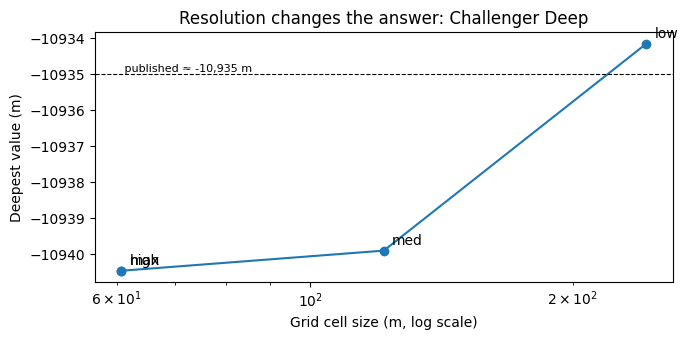

In [3]:
CD_BOX = dict(west=141.9, east=143.0, south=11.1, north=11.6)
rows = []
for res in ["low", "med", "high", "max"]:
    try:
        lo_, la_, zz = sf.load(CD_BOX, res)
        cell = sf.cell_size_m(lo_, la_)[1]
        rows.append((res, cell, np.nanmin(zz)))
        print(f"{res:5s} cell ≈ {cell:6.0f} m   deepest = {np.nanmin(zz):,.0f} m")
    except Exception as e:
        print(f"{res:5s} failed: {e}")

if rows:
    cells, depths = [r[1] for r in rows], [r[2] for r in rows]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(cells, depths, "o-")
    for r, c, d in rows: ax.annotate(r, (c, d), textcoords="offset points", xytext=(6, 4))
    ax.axhline(-10935, ls="--", c="k", lw=0.8); ax.text(cells[-1], -10935, " published ≈ -10,935 m", va="bottom", fontsize=8)
    ax.set(xscale="log", xlabel="Grid cell size (m, log scale)", ylabel="Deepest value (m)",
           title="Resolution changes the answer: Challenger Deep")
    fig.tight_layout(); fig.savefig(sf.FIG_DIR / "02_resolution_depth.png", dpi=200); plt.show()

Share of our region measured by ships: 60.1%
Is our deepest point ship-measured?  yes


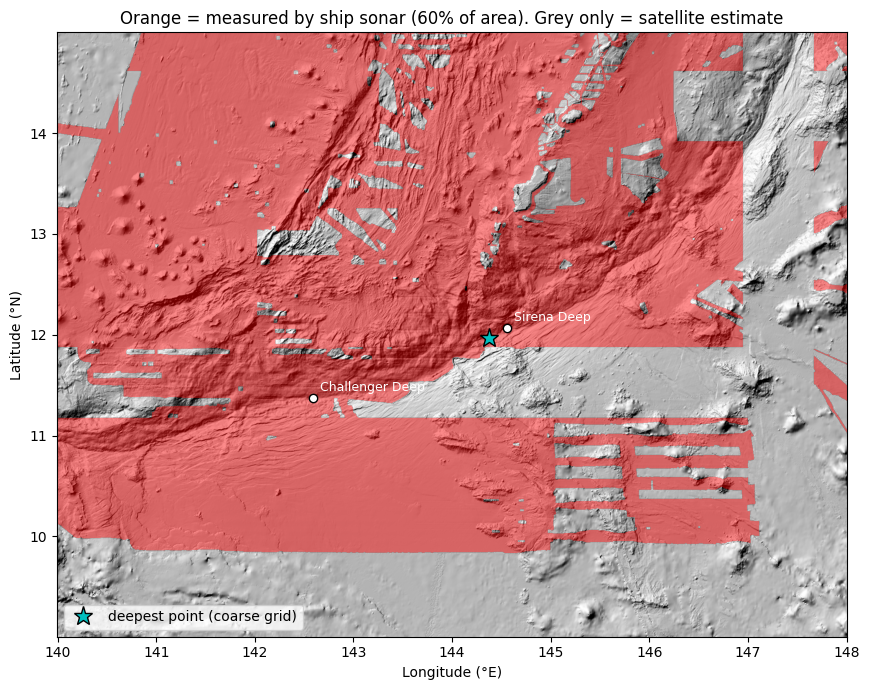

In [4]:
try:
    _, _, zm = sf.load(layer="topo-mask")
    ship = ~np.isnan(zm) if zm.shape == z.shape else None
    if ship is None: print("Mask grid has a different shape; skipping.")
except Exception as e:
    ship = None; print("Could not get the ship-coverage mask:", e)

if ship is not None:
    w = np.cos(np.deg2rad(LAT))
    cover = (w * ship).sum() / w.sum()
    print(f"Share of our region measured by ships: {cover:.1%}")
    print(f"Is our deepest point ship-measured?  {'yes' if ship[i0, j0] else 'NO: it is a satellite estimate'}")

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(shade, extent=extent, origin="lower", cmap="gray", aspect=aspect)
    ax.imshow(np.where(ship, 1, np.nan), extent=extent, origin="lower", cmap="autumn", alpha=0.45, aspect=aspect)
    ax.plot(lon[j0], lat[i0], "c*", ms=14, mec="k", label="deepest point (coarse grid)")
    for name, (la, lo, _) in KNOWN.items(): ax.plot(lo, la, "wo", mec="k"); ax.annotate(name, (lo, la), xytext=(5, 5), textcoords="offset points", color="w", fontsize=9)
    ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
           title=f"Orange = measured by ship sonar ({cover:.0%} of area). Grey only = satellite estimate")
    ax.legend(loc="lower left")
    fig.tight_layout(); fig.savefig(sf.FIG_DIR / "02_ship_coverage.png", dpi=200); plt.show()

In [5]:
def slope_deg(z, dx_rows, dy):
    dzdx = np.full_like(z, np.nan); dzdy = np.full_like(z, np.nan)
    dzdx[:, 1:-1] = (z[:, 2:] - z[:, :-2]) / (2 * dx_rows[:, None])
    dzdy[1:-1, :] = (z[2:, :] - z[:-2, :]) / (2 * dy)
    return np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

S = slope_deg(z, dx, dy)

gy, gx = np.gradient(z, dy, axis=0), np.gradient(z, axis=1) / dx[:, None]
S_np = np.degrees(np.arctan(np.hypot(gx, gy)))
print(f"Max difference vs numpy (interior): {np.nanmax(np.abs(S - S_np)[1:-1, 1:-1]):.2e} degrees")
print(f"Median slope: {np.nanmedian(S):.2f}°   95th percentile: {np.nanpercentile(S, 95):.1f}°   max: {np.nanmax(S):.1f}°")

Max difference vs numpy (interior): 1.15e-05 degrees
Median slope: 2.95°   95th percentile: 15.9°   max: 75.6°


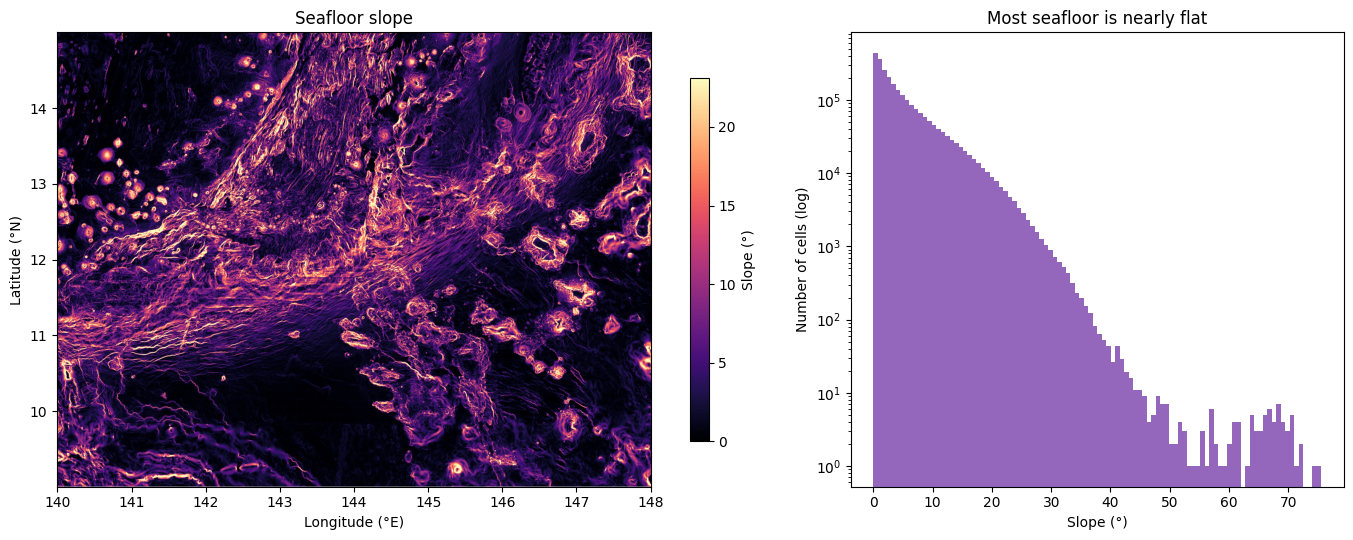

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
im = axes[0].imshow(S, extent=extent, origin="lower", cmap="magma", vmin=0, vmax=np.nanpercentile(S, 99), aspect=aspect)
fig.colorbar(im, ax=axes[0], shrink=0.8, label="Slope (°)")
axes[0].set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title="Seafloor slope")
axes[1].hist(S[~np.isnan(S)], bins=100, color="tab:purple")
axes[1].set(yscale="log", xlabel="Slope (°)", ylabel="Number of cells (log)", title="Most seafloor is nearly flat")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "02_slope.png", dpi=200); plt.show()

every 1 cell(s): cell ≈   0.5 km   median 2.95°   99th pct 23.1°
every 2 cell(s): cell ≈   1.0 km   median 2.77°   99th pct 20.5°
every 4 cell(s): cell ≈   1.9 km   median 2.58°   99th pct 17.6°
every 8 cell(s): cell ≈   3.8 km   median 2.38°   99th pct 14.2°


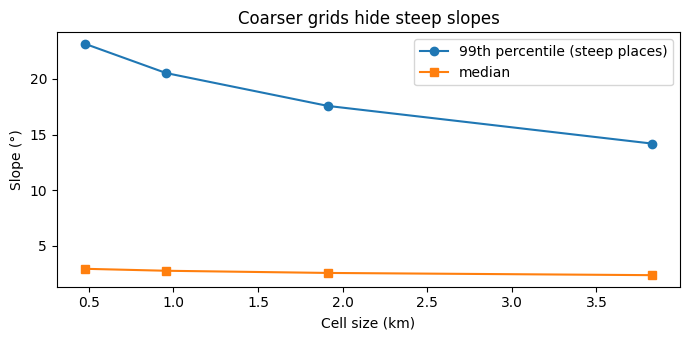

In [7]:
res_rows = []
for k in [1, 2, 4, 8]:
    zk, dxk, dyk = z[::k, ::k], dx[::k] * k, dy * k
    Sk = slope_deg(zk, dxk, dyk)
    res_rows.append((dxk.mean() / 1000, np.nanmedian(Sk), np.nanpercentile(Sk, 99)))
    print(f"every {k} cell(s): cell ≈ {dxk.mean()/1000:5.1f} km   median {res_rows[-1][1]:.2f}°   99th pct {res_rows[-1][2]:.1f}°")

c, med, p99 = map(np.array, zip(*res_rows))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(c, p99, "o-", label="99th percentile (steep places)"); ax.plot(c, med, "s-", label="median")
ax.set(xlabel="Cell size (km)", ylabel="Slope (°)", title="Coarser grids hide steep slopes"); ax.legend()
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "02_slope_vs_resolution.png", dpi=200); plt.show()

Ship-measured cells:   n=1,496,796  median slope 3.31°  95th pct 16.6°
Satellite-only cells:  n=  986,590  median slope 2.48°  95th pct 14.7°


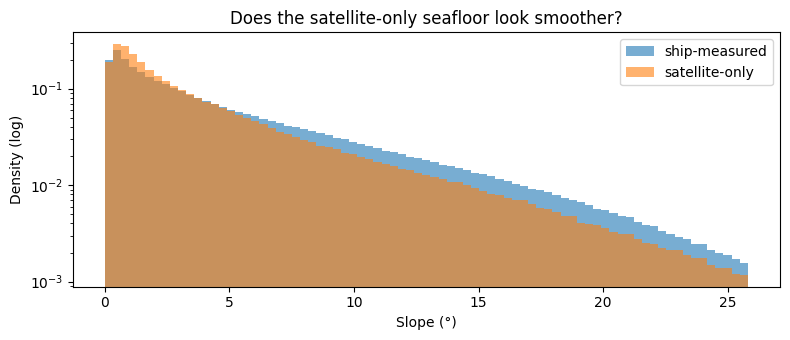

In [8]:
if ship is not None:
    valid = ~np.isnan(S)
    a, b = S[valid & ship], S[valid & ~ship]
    print(f"Ship-measured cells:   n={a.size:>9,}  median slope {np.median(a):.2f}°  95th pct {np.percentile(a, 95):.1f}°")
    print(f"Satellite-only cells:  n={b.size:>9,}  median slope {np.median(b):.2f}°  95th pct {np.percentile(b, 95):.1f}°")
    bins = np.linspace(0, np.nanpercentile(S, 99.5), 80)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(a, bins, density=True, alpha=0.6, label="ship-measured")
    ax.hist(b, bins, density=True, alpha=0.6, label="satellite-only")
    ax.set(yscale="log", xlabel="Slope (°)", ylabel="Density (log)", title="Does the satellite-only seafloor look smoother?")
    ax.legend(); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "02_slope_ship_vs_sat.png", dpi=200); plt.show()

In [9]:
print("KEY NUMBERS")
print(f"  Deepest grid point: {z[i0, j0]:,.0f} m at {lat[i0]:.2f}°N, {lon[j0]:.2f}°E")
for r, c_, d in rows: print(f"  Challenger Deep at '{r}' resolution (~{c_:.0f} m cells): {d:,.0f} m")
if ship is not None:
    print(f"  Ship-measured share of region: {cover:.1%};  deepest point ship-measured: {bool(ship[i0, j0])}")
    print(f"  Median slope ship vs satellite-only: {np.median(a):.2f}° vs {np.median(b):.2f}°")
    print(f"  95th pct slope ship vs satellite-only: {np.percentile(a, 95):.1f}° vs {np.percentile(b, 95):.1f}°")
print(f"  Slope 99th pct at 1x / 8x coarser grid: {p99[0]:.1f}° / {p99[-1]:.1f}°")

KEY NUMBERS
  Deepest grid point: -10,795 m at 11.97°N, 144.37°E
  Challenger Deep at 'low' resolution (~243 m cells): -10,934 m
  Challenger Deep at 'med' resolution (~121 m cells): -10,940 m
  Challenger Deep at 'high' resolution (~61 m cells): -10,940 m
  Challenger Deep at 'max' resolution (~61 m cells): -10,940 m
  Ship-measured share of region: 60.1%;  deepest point ship-measured: True
  Median slope ship vs satellite-only: 3.31° vs 2.48°
  95th pct slope ship vs satellite-only: 16.6° vs 14.7°
  Slope 99th pct at 1x / 8x coarser grid: 23.1° / 14.2°
